In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "ml-20m"

RATINGS_PATH = DATA_DIR / "ratings.csv"
MOVIES_PATH = DATA_DIR / "movies.csv"

In [3]:
file_size = RATINGS_PATH.stat().st_size

print(f"File size: {file_size / (1024**2):.2f} MB")

File size: 508.73 MB


In [4]:
ratings_sample = pd.read_csv(
    RATINGS_PATH,
    nrows=10_000
)

ratings_sample.head()

,userId,movieId,rating,timestamp
0,1,2,3.5,1112486027
1,1,29,3.5,1112484676
2,1,32,3.5,1112484819
3,1,47,3.5,1112484727
4,1,50,3.5,1112484580


In [5]:
ratings_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     10000 non-null  int64  
 1   movieId    10000 non-null  int64  
 2   rating     10000 non-null  float64
 3   timestamp  10000 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 312.6 KB


In [6]:
ratings_sample.describe()

,userId,movieId,rating,timestamp
count,10000.000000,10000.000000,10000.000000,1.000000e+04
mean,45.303200,6397.601500,3.644350,1.059829e+09
std,26.523277,15921.669731,1.051736,1.602419e+08
min,1.000000,1.000000,0.500000,8.310510e+08
25%,23.000000,590.000000,3.000000,9.451761e+08
50%,50.000000,1641.000000,4.000000,1.000099e+09
75%,66.000000,3450.250000,4.500000,1.197063e+09
max,91.000000,125916.000000,5.000000,1.424845e+09


In [7]:
ratings_sample["userId"].value_counts()

userId
54    710
58    657
24    506
11    504
91    379
     ... 
81     23
36     20
37     20
39     20
52     20
Name: count, Length: 91, dtype: int64

In [8]:
movies = pd.read_csv(MOVIES_PATH)

print(movies.shape)
movies.head()

(27278, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [9]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  27278 non-null  int64
 1   title    27278 non-null  str  
 2   genres   27278 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.7 MB


In [10]:
movies["genres"].value_counts().head(10)

genres
Drama                   4520
Comedy                  2294
Documentary             1942
Comedy|Drama            1264
Drama|Romance           1075
Comedy|Romance           757
Comedy|Drama|Romance     605
Horror                   565
Crime|Drama              448
Drama|Thriller           426
Name: count, dtype: int64

In [11]:
movies["movieId"].duplicated().sum()

np.int64(0)

In [12]:
ratings_sample["rating"].value_counts().sort_index()

rating
0.5     112
1.0     294
1.5      77
2.0     684
2.5     238
3.0    2303
3.5     664
4.0    2989
4.5     738
5.0    1901
Name: count, dtype: int64

Chunk Processing

In [13]:
from tqdm.auto import tqdm

In [14]:
CHUNK_SIZE = 500_000

DTYPES = {
    "userId": "int32",
    "movieId": "int32",
    "rating": "float32",
    "timestamp": "int32"
}

In [15]:
total_rows = 0

unique_users = set()
unique_movies = set()

rating_distribution = pd.Series(dtype="int64")

reader = pd.read_csv(
    RATINGS_PATH,
    chunksize=CHUNK_SIZE,
    dtype=DTYPES
)

for chunk in tqdm(reader, desc="Processing ratings"):

    total_rows += len(chunk)

    unique_users.update(chunk["userId"].unique())
    unique_movies.update(chunk["movieId"].unique())

    chunk_ratings = chunk["rating"].value_counts()

    rating_distribution = rating_distribution.add(
        chunk_ratings,
        fill_value=0
    )

print("Total ratings:", total_rows)
print("Unique users:", len(unique_users))
print("Unique movies:", len(unique_movies))

print("\nRating distribution:")
print(rating_distribution.sort_index())

Processing ratings: 0it [00:00, ?it/s]

Total ratings: 20000263
Unique users: 138493
Unique movies: 26744

Rating distribution:
rating
0.5     239125.0
1.0     680732.0
1.5     279252.0
2.0    1430997.0
2.5     883398.0
3.0    4291193.0
3.5    2200156.0
4.0    5561926.0
4.5    1534824.0
5.0    2898660.0
dtype: float64


In [16]:
n_users = len(unique_users)
n_movies = len(unique_movies)

total_possible_interactions = n_users * n_movies

density = total_rows / total_possible_interactions
sparsity = 1 - density

print(f"Possible interactions: {total_possible_interactions:,}")
print(f"Actual interactions: {total_rows:,}")
print(f"Matrix density: {density:.4%}")
print(f"Matrix sparsity: {sparsity:.4%}")

Possible interactions: 3,703,856,792
Actual interactions: 20,000,263
Matrix density: 0.5400%
Matrix sparsity: 99.4600%


In [17]:
from collections import Counter

user_activity = Counter()
movie_popularity = Counter()

reader = pd.read_csv(
    RATINGS_PATH,
    chunksize=CHUNK_SIZE,
    dtype=DTYPES
)

for chunk in tqdm(reader, desc="Calculating activity"):

    user_activity.update(
        chunk["userId"].value_counts().to_dict()
    )

    movie_popularity.update(
        chunk["movieId"].value_counts().to_dict()
    )

Calculating activity: 0it [00:00, ?it/s]

In [18]:
user_activity_df = (
    pd.Series(user_activity, name="rating_count")
    .rename_axis("userId")
    .reset_index()
)

movie_popularity_df = (
    pd.Series(movie_popularity, name="rating_count")
    .rename_axis("movieId")
    .reset_index()
)

In [19]:
user_activity_df.nlargest(10, "rating_count")

,userId,rating_count
117591,118205,9254
6743,8405,7515
79393,82418,5646
121024,121535,5520
124478,125794,5491
72647,74142,5447
34395,34576,5356
131467,131904,5330
82853,83090,5169
58694,59477,4988


In [20]:
movie_popularity_df.nlargest(10, "rating_count").merge(
    movies,
    on="movieId",
    how="left"
)

,movieId,rating_count,title,genres
0,296,67310,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
1,356,66172,Forrest Gump (1994),Comedy|Drama|Romance|War
2,318,63366,"Shawshank Redemption, The (1994)",Crime|Drama
3,593,63299,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
4,480,59715,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
5,260,54502,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
6,110,53769,Braveheart (1995),Action|Drama|War
7,589,52244,Terminator 2: Judgment Day (1991),Action|Sci-Fi
8,2571,51334,"Matrix, The (1999)",Action|Sci-Fi|Thriller
9,527,50054,Schindler's List (1993),Drama|War


In [21]:
import matplotlib.pyplot as plt

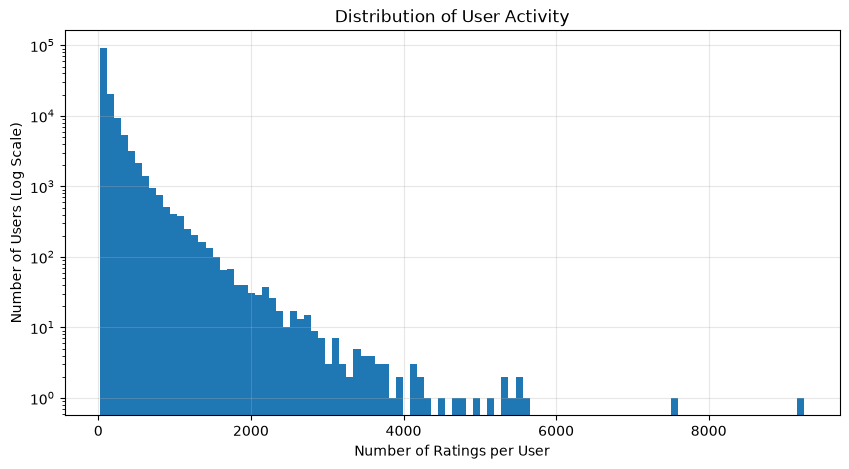

In [22]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_activity_df["rating_count"],
    bins=100,
    log=True
)

plt.title("Distribution of User Activity")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users (Log Scale)")
plt.grid(alpha=0.3)

plt.show()

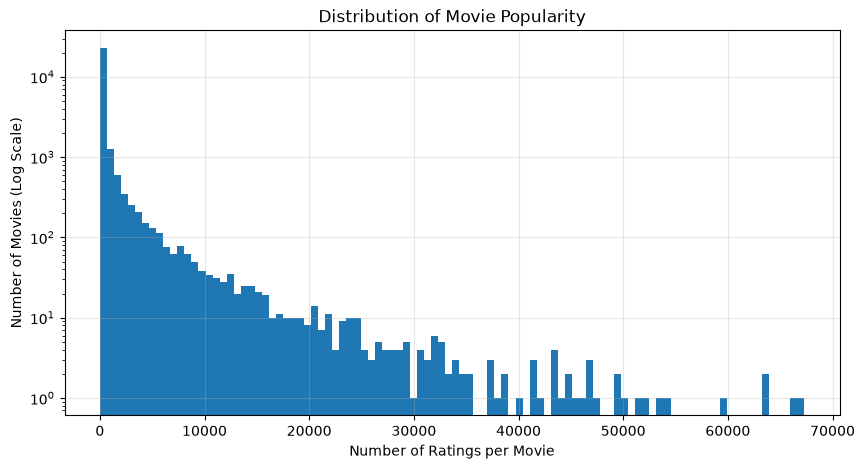

In [23]:
plt.figure(figsize=(10, 5))

plt.hist(
    movie_popularity_df["rating_count"],
    bins=100,
    log=True
)

plt.title("Distribution of Movie Popularity")
plt.xlabel("Number of Ratings per Movie")
plt.ylabel("Number of Movies (Log Scale)")
plt.grid(alpha=0.3)

plt.show()

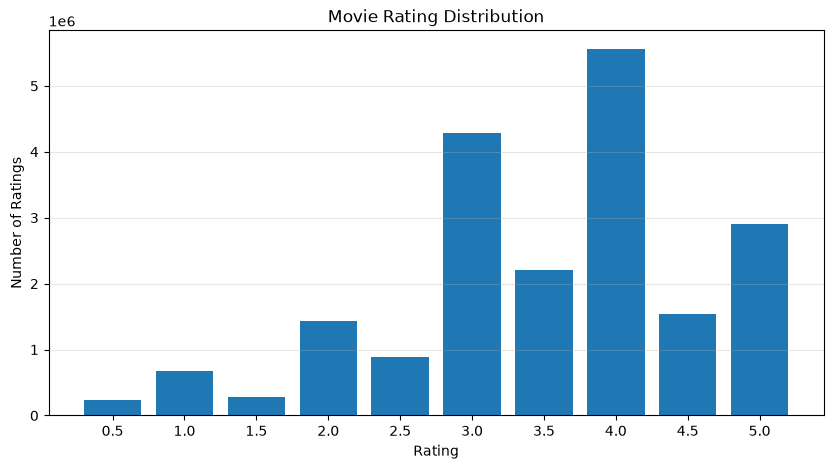

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    rating_distribution.index.astype(str),
    rating_distribution.values
)

plt.title("Movie Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [25]:
PARQUET_DIR = PROJECT_ROOT / "data" / "processed" / "ratings_parquet"

PARQUET_DIR.mkdir(parents=True, exist_ok=True)

reader = pd.read_csv(
    RATINGS_PATH,
    chunksize=CHUNK_SIZE,
    dtype=DTYPES
)

for i, chunk in enumerate(tqdm(reader, desc="Converting to Parquet")):

    output_path = PARQUET_DIR / f"part-{i:05d}.parquet"

    chunk.to_parquet(
        output_path,
        engine="pyarrow",
        compression="snappy",
        index=False
    )

print("Conversion completed!")

Converting to Parquet: 0it [00:00, ?it/s]

Conversion completed!


In [26]:
first_part = pd.read_parquet(
    PARQUET_DIR / "part-00000.parquet"
)

print(first_part.info())
print(first_part.head())

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     500000 non-null  int32  
 1   movieId    500000 non-null  int32  
 2   rating     500000 non-null  float32
 3   timestamp  500000 non-null  int32  
dtypes: float32(1), int32(3)
memory usage: 7.6 MB
None
   userId  movieId  rating   timestamp
0       1        2     3.5  1112486027
1       1       29     3.5  1112484676
2       1       32     3.5  1112484819
3       1       47     3.5  1112484727
4       1       50     3.5  1112484580


In [27]:
parquet_size = sum(
    file.stat().st_size
    for file in PARQUET_DIR.glob("*.parquet")
)

print(f"Parquet size: {parquet_size / (1024**2):.2f} MB")

Parquet size: 138.67 MB


In [29]:
parquet_files = sorted(PARQUET_DIR.glob("*.parquet"))

print("Number of partitions:", len(parquet_files))
print(
    pd.read_parquet(
        parquet_files[0]
    ).dtypes
)

Number of partitions: 41
userId         int32
movieId        int32
rating       float32
timestamp      int32
dtype: object


In [30]:
import duckdb

con = duckdb.connect()

In [31]:
query = f"""
SELECT
    COUNT(*) AS total_ratings,
    COUNT(DISTINCT userId) AS unique_users,
    COUNT(DISTINCT movieId) AS unique_movies
FROM read_parquet('{PARQUET_DIR.as_posix()}/*.parquet')
"""

con.execute(query).df()

,total_ratings,unique_users,unique_movies
0,20000263,138493,26744
